In [ ]:
%pip install matplotlib

# Analyse de la concentration de CO₂ à Mauna Loa

## Introduction

Depuis 1958, la concentration de dioxyde de carbone (CO₂) dans l'atmosphère est mesurée régulièrement à l'observatoire de Mauna Loa,
à Hawaii. Ces mesures constituent la série temporelle connue sous le nom de « Keeling Curve ».

L'objectif de cette étude est d'analyser les observations hebdomadaires de concentration de CO₂ afin d'identifier et de séparer deux phénomènes superposés :

1. une évolution lente et systématique de la concentration de CO₂ ;
2. une oscillation périodique associée aux variations saisonnières.

Nous chercherons ensuite à caractériser cette oscillation, à construire un modèle simple de la tendance à long terme et à utiliser ce modèle pour effectuer une extrapolation jusqu'en 2025.

Enfin, les observations de 2025 seront utilisées pour évaluer la qualité de la prévision.

## Données

Les données utilisées sont issues du Scripps CO₂ Program. Le fichier analysé est le fichier contenant les observations hebdomadaires de
Mauna Loa.

La version locale du fichier utilisée dans cette étude doit être conservée afin de garantir la reproductibilité de l'analyse.

## 1. Importation des données

Nous commençons par importer les bibliothèques nécessaires à l'analyse.

`pandas` sera utilisé pour manipuler les données sous forme de tableau, `numpy` pour les calculs numériques et `matplotlib` pour les  représentations graphiques.

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Chargement du fichier

Le fichier fourni par le Scripps CO₂ Program contient plusieurs lignes d'informations descriptives avant les observations proprement dites.

Dans notre version du fichier, les observations commencent après 56 lignes d'en-tête. Nous indiquons donc à `pandas` de les ignorer.

Les deux colonnes correspondent à la date de l'observation et à la concentration de CO₂ en parties par million (ppm).

In [25]:
df = pd.read_csv(
    "weekly_in_situ_co2_mlo.csv",
    skiprows=56,
    names=["WeekDate", "CO2"]
)

df.head()

,WeekDate,CO2
0,1958-07-05,315.85
1,1958-07-12,315.85
2,1958-07-19,315.46
3,1958-07-26,315.59
4,1958-08-02,315.64


### Vérification de la structure des données

Avant de commencer l'analyse, nous vérifions la taille du jeu de données, les dates disponibles et la présence éventuelle de valeurs manquantes.

Cette étape est importante car une analyse de série temporelle peut être faussée par des observations manquantes ou par des dates mal interprétées.

In [4]:
print("Nombre de mesures :", len(df))
print("Première date :", df["WeekDate"].iloc[0])
print("Dernière date :", df["WeekDate"].iloc[-1])
print("Valeurs manquantes :", df["CO2"].isna().sum())

Nombre de mesures : 3494
Première date : 1958-07-05
Dernière date : 2026-10-17
Valeurs manquantes : 0


### Observation

Le jeu de données contient 3494 observations hebdomadaires, couvrant la période du 5 juillet 1958 au 17 octobre 2026.
Aucune valeur manquante n'est présente dans les deux variables utilisées pour l'analyse.

Le jeu de données est donc suffisamment complet pour poursuivre l'étude de l'évolution temporelle du CO₂.

In [38]:
## Conversion des dates : 
#La colonne `WeekDate` est initialement lue comme du texte.
#Nous la convertissons en objet `datetime` afin de pouvoir effectuer
#des calculs et des représentations graphiques utilisant correctement le temps.
df["WeekDate"] = pd.to_datetime(df["WeekDate"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3494 entries, 0 to 3493
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   WeekDate    3494 non-null   datetime64[ns]
 1   CO2         3494 non-null   float64       
 2   CO2_smooth  3443 non-null   float64       
 3   seasonal    3443 non-null   float64       
dtypes: datetime64[ns](1), float64(3)
memory usage: 109.3 KB


## 2. Exploration de l'évolution du CO₂

### Visualisation de la série temporelle

Nous représentons maintenant l'ensemble des observations hebdomadaires en fonction du temps.

L'objectif de ce premier graphique n'est pas encore de construire un modèle, mais simplement d'identifier visuellement les structures
présentes dans les données.

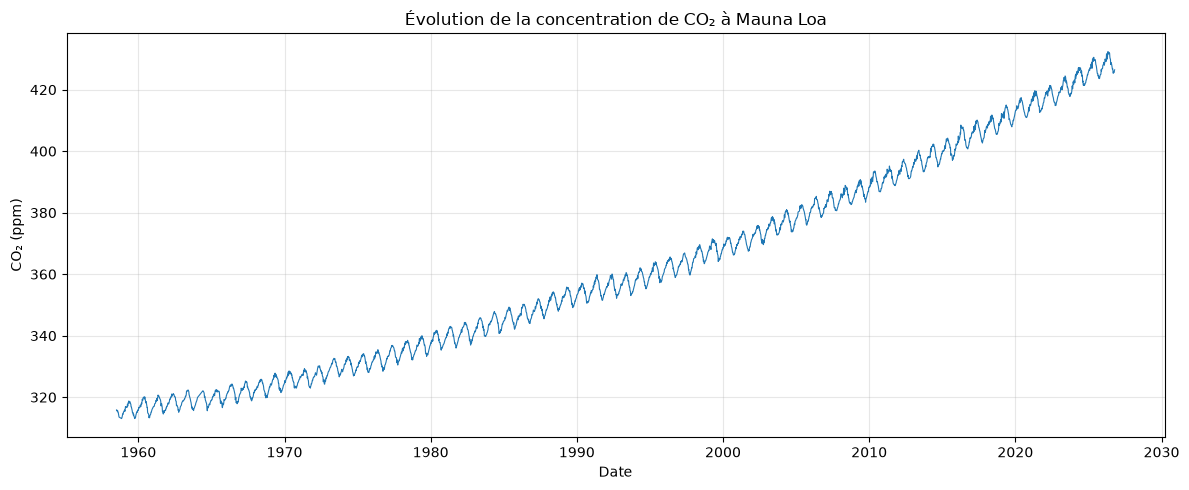

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(df["WeekDate"], df["CO2"], linewidth=0.8)

plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Évolution de la concentration de CO₂ à Mauna Loa")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

La série présente deux caractéristiques principales.

Tout d'abord, la concentration moyenne de CO₂ augmente fortement au cours de la période étudiée. Cette évolution correspond à une
tendance lente à long terme.

Ensuite, la courbe présente des variations régulières autour de cette tendance. Ces variations se répètent approximativement chaque année
et correspondent à une oscillation saisonnière.

Les deux phénomènes sont donc superposés dans les observations.

La suite de l'analyse consiste à les séparer afin de pouvoir caractériser l'oscillation et modéliser indépendamment l'évolution
lente de la concentration de CO₂.

## 3. Séparation de la tendance et de l'oscillation saisonnière

La série temporelle observée combine deux phénomènes de nature différente.

La concentration de CO₂ évolue lentement au cours des décennies, tandis qu'une variation plus rapide et presque périodique se répète chaque année.

Pour étudier séparément ces deux composantes, nous allons construire une estimation de la tendance à long terme à l'aide d'une moyenne mobile.

Une période d'environ 52 semaines correspond à une année. Une moyenne mobile sur 52 semaines permet donc de réduire fortement les variations saisonnières tout en conservant l'évolution lente de la concentration.

In [30]:
df["CO2_smooth"] = df["CO2"].rolling(
    window=52,
    center=True
).mean()

### Pourquoi une moyenne mobile ?

Pour chaque date, la moyenne mobile calcule la moyenne des observations situées autour de cette date.

Les variations saisonnières étant beaucoup plus rapides que l'évolution sur plusieurs décennies, elles sont en grande partie lissées par cette opération.

La courbe obtenue constitue donc une approximation de la composante lente de la série temporelle.

Il faut noter que la moyenne mobile centrée ne peut pas être calculée aux extrémités de la série, car elle nécessite des observations avant et après la date considérée.

### Comparaison des observations avec la tendance lissée

Nous représentons maintenant simultanément les données hebdomadaires
et la moyenne mobile.

Cette représentation permet de vérifier visuellement si le lissage
a effectivement séparé les variations rapides de l'évolution lente.

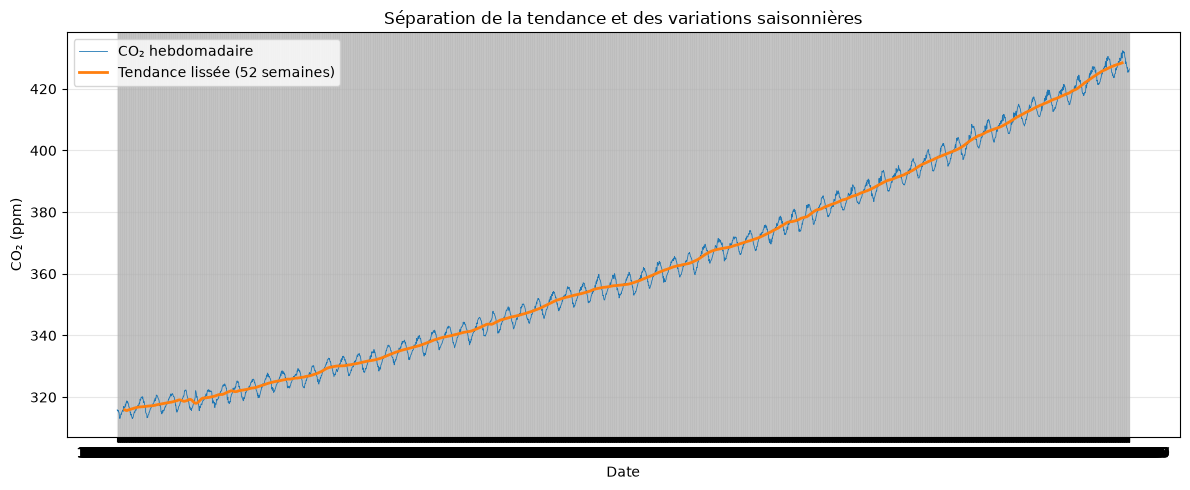

In [31]:
plt.figure(figsize=(12, 5))

plt.plot(
    df["WeekDate"],
    df["CO2"],
    linewidth=0.6,
    label="CO₂ hebdomadaire"
)

plt.plot(
    df["WeekDate"],
    df["CO2_smooth"],
    linewidth=2,
    label="Tendance lissée (52 semaines)"
)

plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Séparation de la tendance et des variations saisonnières")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

La courbe hebdomadaire présente des oscillations régulières autour d'une tendance générale croissante.

La moyenne mobile suit cette évolution générale tout en supprimant une grande partie des fluctuations de courte période.

Nous pouvons donc utiliser la moyenne mobile comme estimation de la tendance lente recherchée dans l'énoncé.

La différence entre la mesure hebdomadaire et cette tendance permettra maintenant d'étudier séparément l'oscillation saisonnière.

## 4. Analyse de l'oscillation saisonnière

Une fois la tendance lente estimée, nous pouvons calculer la composante rapide de la série.

Nous définissons l'oscillation résiduelle comme :

    oscillation = CO₂ observé − tendance lissée

Si la moyenne mobile représente correctement la tendance à long terme, cette différence doit principalement contenir les variations saisonnières et les petites fluctuations restantes.

In [32]:
df["seasonal"] = df["CO2"] - df["CO2_smooth"]

print("Amplitude maximale :", df["seasonal"].max())
print("Amplitude minimale :", df["seasonal"].min())
print("Amplitude crête-à-crête :", 
      df["seasonal"].max() - df["seasonal"].min())

Amplitude maximale : 4.984807692307697
Amplitude minimale : -4.535769230769233
Amplitude crête-à-crête : 9.52057692307693


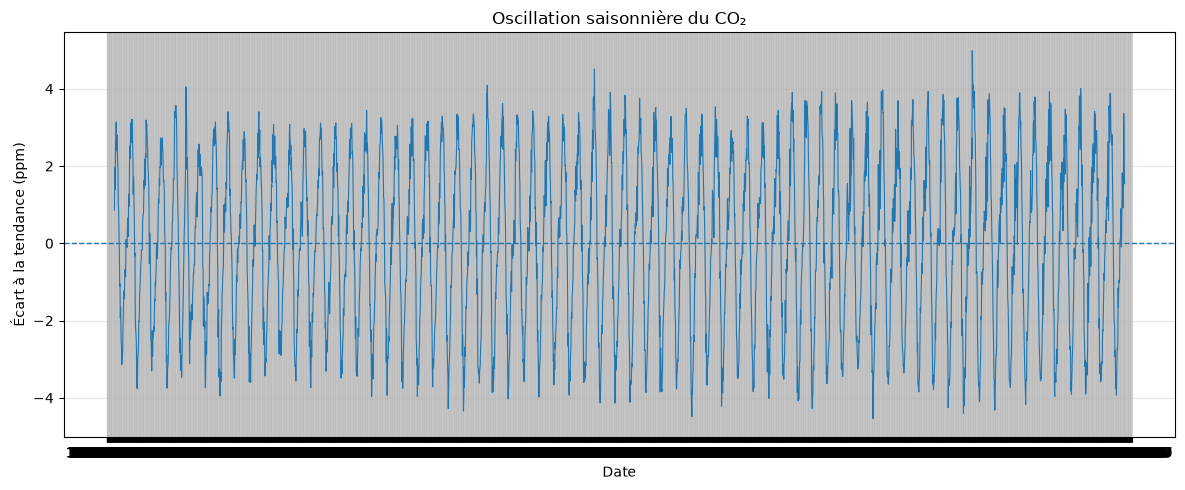

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(df["WeekDate"], df["seasonal"], linewidth=0.8)

plt.axhline(0, linestyle="--", linewidth=1)

plt.xlabel("Date")
plt.ylabel("Écart à la tendance (ppm)")
plt.title("Oscillation saisonnière du CO₂")

plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

La composante extraite oscille autour de zéro et présente une succession de maxima et de minima qui se répète régulièrement au cours du temps.

Cette répétition montre que les fluctuations ne sont pas aléatoires : elles possèdent une structure périodique.

La période semble être proche d'une année, ce qui est cohérent avec une variation saisonnière liée au cycle annuel de la biosphère.

Nous allons maintenant quantifier cette périodicité plutôt que de nous limiter à une observation visuelle.

## 5. Caractérisation de la période

Pour estimer la période de l'oscillation, nous utilisons
l'autocorrélation de la composante saisonnière.

L'idée est de comparer la série avec elle-même après un décalage
de plusieurs semaines.

Si l'oscillation se répète chaque année, la corrélation doit être
particulièrement forte pour un décalage proche de 52 semaines.

In [36]:
seasonal_clean = df["seasonal"].dropna()

# Autocorrélations pour des décalages compris entre 40 et 65 semaines
lags = range(40, 66)

autocorrelations = [
    seasonal_clean.autocorr(lag=lag)
    for lag in lags
]

best_lag = lags[np.argmax(autocorrelations)]
best_corr = max(autocorrelations)

print("Décalage donnant la corrélation maximale :", best_lag, "semaines")
print("Corrélation correspondante :", best_corr)

Décalage donnant la corrélation maximale : 51 semaines
Corrélation correspondante : 0.9304380136433635


### Résultat

Le décalage présentant la corrélation maximale est proche de 52 semaines.

Cela confirme quantitativement que l'oscillation observée possède une période approximativement annuelle.

Nous pouvons donc caractériser cette composante comme une oscillation saisonnière de période proche d'un an.

## 6. Modélisation de la tendance à long terme

Après avoir séparé l'oscillation saisonnière, nous disposons d'une estimation de la tendance lente grâce à la moyenne mobile.

L'objectif est maintenant de construire un modèle mathématique simple capable de représenter cette évolution et, ensuite, de l'extrapoler.

Nous commençons par un modèle linéaire. Ce choix constitue une première approximation simple : il suppose que la concentration de CO₂ augmente à un rythme constant au cours du temps.

Nous vérifierons ensuite si cette hypothèse est compatible avec les données.

In [39]:
# On conserve uniquement les valeurs pour lesquelles
# la moyenne mobile est disponible
tendance = df.dropna(subset=["CO2_smooth"]).copy()

# Temps exprimé en années depuis le début de 1958
t = (
    tendance["WeekDate"] - pd.Timestamp("1958-01-01")
).dt.days / 365.25

# Ajustement du modèle linéaire :
# CO2(t) = a*t + b
a, b = np.polyfit(
    t,
    tendance["CO2_smooth"],
    1
)

tendance["CO2_lineaire"] = a * t + b

print("Pente :", round(a, 4), "ppm/an")
print("Ordonnée à l'origine :", round(b, 4))

Pente : 1.6788 ppm/an
Ordonnée à l'origine : 303.0663


### Interprétation du modèle linéaire

Le modèle obtenu possède une pente d'environ 1,68 ppm/an.

Cette pente représente l'augmentation moyenne de la concentration de CO₂ selon le modèle sur l'ensemble de la période étudiée.

Cependant, une pente constante est une hypothèse forte. Il faut donc vérifier visuellement si une droite représente correctement la tendance sur toute la période.

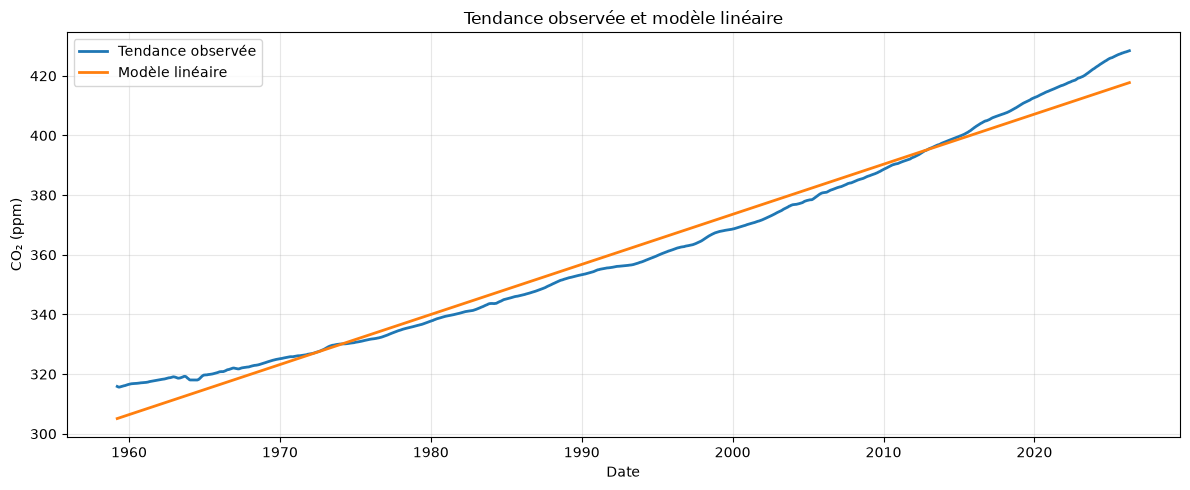

In [40]:
plt.figure(figsize=(12, 5))

plt.plot(
    tendance["WeekDate"],
    tendance["CO2_smooth"],
    label="Tendance observée",
    linewidth=2
)

plt.plot(
    tendance["WeekDate"],
    tendance["CO2_lineaire"],
    label="Modèle linéaire",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Tendance observée et modèle linéaire")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Observation

Le modèle linéaire représente correctement l'évolution générale, mais des écarts apparaissent progressivement entre le modèle et la tendance observée.

En particulier, la tendance observée est plus élevée que la droite dans les dernières années.

Cela indique que l'hypothèse d'une augmentation strictement constante n'est pas parfaitement adaptée à la série étudiée.

Nous allons donc tester un modèle quadratique, qui permet à la pente d'évoluer progressivement avec le temps.

## 6.4 Modèle quadratique

Nous considérons maintenant un modèle de la forme : CO₂(t) = a t² + b t + c

Contrairement au modèle linéaire, ce modèle permet à la vitesse d'évolution du CO₂ de varier avec le temps.

Il reste suffisamment simple pour être interprétable tout en permettant de représenter la courbure visible dans les données.

In [43]:
# Modèle quadratique
a2, b2, c2 = np.polyfit(t, tendance["CO2_smooth"], 2)

tendance["CO2_quadratique"] = (
    a2 * t**2 + b2 * t + c2
)

print("Coefficient a =", a2)
print("Coefficient b =", b2)
print("Coefficient c =", c2)

Coefficient a = 0.01366738598695199
Coefficient b = 0.724423320396854
Coefficient c = 314.65831297736446


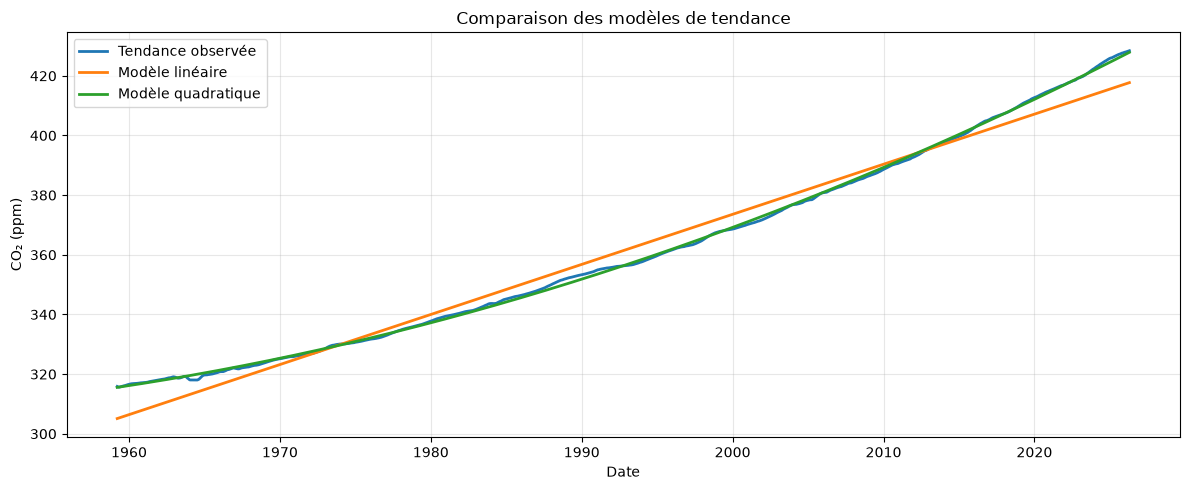

In [44]:
plt.figure(figsize=(12, 5))

plt.plot(
    tendance["WeekDate"],
    tendance["CO2_smooth"],
    label="Tendance observée",
    linewidth=2
)

plt.plot(
    tendance["WeekDate"],
    tendance["CO2_lineaire"],
    label="Modèle linéaire",
    linewidth=2
)

plt.plot(
    tendance["WeekDate"],
    tendance["CO2_quadratique"],
    label="Modèle quadratique",
    linewidth=2
)

plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Comparaison des modèles de tendance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Analyse

Le modèle quadratique suit davantage la courbure de la tendance observée, en particulier dans les dernières décennies.

Le modèle linéaire sous-estime progressivement la concentration observée dans la partie récente de la série.

Nous retenons donc le modèle quadratique comme modèle simple de la contribution lente pour la suite de l'analyse.

### Évaluation quantitative des modèles

La comparaison graphique permet d'identifier les différences entre les modèles, mais nous pouvons également les quantifier.

Nous calculons ici l'erreur quadratique moyenne (RMSE).

Une RMSE plus faible indique que le modèle reste, en moyenne, plus proche de la tendance observée.

In [45]:
rmse_lineaire = np.sqrt(
    np.mean(
        (tendance["CO2_smooth"] - tendance["CO2_lineaire"])**2
    )
)

rmse_quadratique = np.sqrt(
    np.mean(
        (tendance["CO2_smooth"] - tendance["CO2_quadratique"])**2
    )
)

print("RMSE modèle linéaire :", round(rmse_lineaire, 3), "ppm")
print("RMSE modèle quadratique :", round(rmse_quadratique, 3), "ppm")

RMSE modèle linéaire : 4.619 ppm
RMSE modèle quadratique : 0.693 ppm


### Interprétation

La RMSE permet de comparer quantitativement les deux modèles.

Le modèle quadratique présente une erreur plus faible que le modèle linéaire. Il représente donc mieux la tendance observée sur la période
d'ajustement.

Nous utiliserons par conséquent le modèle quadratique pour réaliser l'extrapolation vers 2025.

## 7. Extrapolation et validation en 2025

Pour tester réellement la capacité prédictive du modèle, nous ne devons pas utiliser les observations de 2025 pour construire le modèle.

Nous ajustons donc à nouveau le modèle quadratique uniquement sur les données disponibles avant le 1er janvier 2025.

Le modèle obtenu sera ensuite utilisé pour prédire la tendance en 2025.

Les observations réelles de 2025 seront conservées à part afin de pouvoir comparer la prévision au résultat effectivement observé.

In [19]:
# On garde uniquement les données jusqu'à fin 2024
train = tendance[tendance["WeekDate"] < "2025-01-01"].copy()

# Temps en années depuis 1958
t_train = (
    train["WeekDate"] - pd.Timestamp("1958-01-01")
).dt.days / 365.25

# Ajustement du modèle quadratique jusqu'à 2024
a25, b25, c25 = np.polyfit(
    t_train,
    train["CO2_smooth"],
    2
)

# Prévision au 1er janvier 2025
t_2025 = (
    pd.Timestamp("2025-01-01") - pd.Timestamp("1958-01-01")
).days / 365.25

prediction_2025 = (
    a25 * t_2025**2
    + b25 * t_2025
    + c25
)

print("Prévision du modèle pour 2025 :", prediction_2025, "ppm")

Prévision du modèle pour 2025 : 424.3661658443656 ppm


### Résultat de l'extrapolation

Le modèle quadratique, ajusté sans utiliser les observations de 2025, prévoit une concentration d'environ 424,37 ppm pour le début de 2025.

Cette valeur constitue une véritable prévision hors échantillon : les observations de l'année prédite n'ont pas participé à l'estimation
des paramètres du modèle.

Nous pouvons donc maintenant confronter cette prévision aux observations réelles de 2025.

In [46]:
observations_2025 = tendance[
    (tendance["WeekDate"] >= "2025-01-01") &
    (tendance["WeekDate"] < "2026-01-01")
].copy()

moyenne_2025 = observations_2025["CO2_smooth"].mean()

erreur_2025 = moyenne_2025 - prediction_2025
erreur_relative = (
    abs(erreur_2025) / moyenne_2025 * 100
)

print(
    "Prévision du modèle :",
    round(prediction_2025, 2),
    "ppm"
)

print(
    "Tendance réellement observée en 2025 :",
    round(moyenne_2025, 2),
    "ppm"
)

print(
    "Écart :",
    round(erreur_2025, 2),
    "ppm"
)

print(
    "Erreur relative :",
    round(erreur_relative, 2),
    "%"
)

Prévision du modèle : 424.37 ppm
Tendance réellement observée en 2025 : 426.95 ppm
Écart : 2.58 ppm
Erreur relative : 0.6 %


### Interprétation de la validation

La prévision du modèle est d'environ 424,37 ppm, tandis que la tendance réellement observée en 2025 est d'environ 426,95 ppm.

L'écart entre les deux valeurs est donc d'environ 2,58 ppm.

Le modèle sous-estime légèrement la concentration observée en 2025, mais il reproduit correctement l'ordre de grandeur et l'évolution
générale de la tendance.

Cette comparaison montre également les limites d'un modèle quadratique simple : une extrapolation sur une année peut être raisonnable, mais elle ne permet pas de reproduire toutes les variations réelles de la concentration atmosphérique.

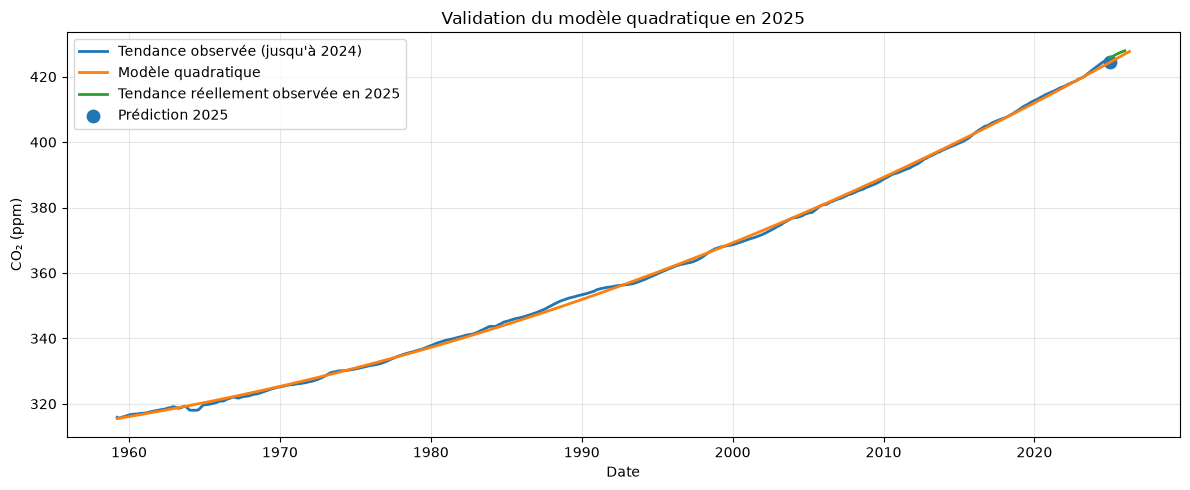

In [47]:
plt.figure(figsize=(12, 5))

# Tendance utilisée pour construire le modèle
plt.plot(
    train["WeekDate"],
    train["CO2_smooth"],
    label="Tendance observée (jusqu'à 2024)",
    linewidth=2
)

# Modèle quadratique
tous_les_t = (
    tendance["WeekDate"] - pd.Timestamp("1958-01-01")
).dt.days / 365.25

modele_tout = (
    a25 * tous_les_t**2
    + b25 * tous_les_t
    + c25
)

plt.plot(
    tendance["WeekDate"],
    modele_tout,
    label="Modèle quadratique",
    linewidth=2
)

# Tendance observée en 2025
plt.plot(
    observations_2025["WeekDate"],
    observations_2025["CO2_smooth"],
    label="Tendance réellement observée en 2025",
    linewidth=2
)

# Prédiction 2025
plt.scatter(
    [pd.Timestamp("2025-01-01")],
    [prediction_2025],
    s=80,
    label="Prédiction 2025"
)

plt.xlabel("Date")
plt.ylabel("CO₂ (ppm)")
plt.title("Validation du modèle quadratique en 2025")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

### Analyse du graphique

Le modèle quadratique suit la tendance générale observée jusqu'à 2024.

Lorsque l'on prolonge ce modèle jusqu'en 2025, la prédiction reste proche de la tendance effectivement observée pendant cette année.

La différence entre la prédiction et l'observation réelle montre cependant que le modèle ne décrit pas parfaitement l'évolution du CO₂.

Cette différence est attendue : le modèle quadratique est une approximation simple de la tendance et ne prend pas en compte tous
les mécanismes responsables de l'évolution de la concentration atmosphérique.

# 10. Conclusion

Cette analyse avait pour objectif d'étudier les observations hebdomadaires de concentration de CO₂ mesurées à Mauna Loa depuis 1958.

### 1. Mise en évidence des deux phénomènes

La représentation de la série temporelle montre deux phénomènes superposés.
Une tendance lente correspond à l'augmentation progressive de la concentration atmosphérique de CO₂.
Une oscillation plus rapide se répète approximativement chaque année.
L'analyse de la composante résiduelle confirme une période proche de 52 semaines.

### 2. Séparation et modélisation

Une moyenne mobile sur 52 semaines a été utilisée pour obtenir une estimation de la tendance lente.

La différence entre les observations et cette tendance permet d'isoler approximativement l'oscillation saisonnière.

L'amplitude crête-à-crête obtenue est d'environ 9,5 ppm, soit une amplitude d'environ 4,8 ppm autour de la tendance.

Pour représenter l'évolution lente, nous avons comparé un modèle linéaire et un modèle quadratique.

Le modèle quadratique représente mieux la courbure observée dans la série et a donc été retenu pour l'extrapolation.

### 3. Extrapolation et validation en 2025

Afin d'effectuer une véritable validation, le modèle quadratique a été ajusté uniquement à partir des données disponibles avant 2025.

Le modèle prédit une concentration d'environ 424,37 ppm pour le début de 2025.

La tendance réellement observée en 2025 est d'environ 426,95 ppm, soit un écart d'environ 2,58 ppm.

Le modèle fournit donc une approximation raisonnable de l'évolution à long terme, mais son erreur montre également les limites d'un modèle
quadratique simple pour extrapoler une série climatique réelle.

## Bilan

L'analyse permet ainsi de distinguer une oscillation saisonnière régulière d'une tendance de fond croissante.

Elle montre également l'intérêt d'une démarche reproductible : les données sont conservées localement, les transformations sont
explicitement décrites et les résultats du modèle sont confrontés à des observations qui n'ont pas servi à son ajustement.